# Egen lab

Använder pandas för att analysera data frn årets val. Data kommer från Valmyndighetern https://www.val.se/valresultat-och-statistik/statistik-och-data/radata-val-2026


In [84]:
import sys

import pandas as pd


In [85]:
print(pd.__version__)
print(sys.version)

3.0.5
3.14.10 (main, Oct 26 2026, 13:59:48) [Clang 23.1.3 ]


In [86]:
slutg_riksdag = pd.read_excel('data/roster-per-distrikt-slutligt-antal-roster-inklusive-totalt-valdeltagande-riksdagsvalet-2026.xlsx') # Slutgiltigt valresultat till riksdagen
prel_riksdag = pd.read_excel('data/preliminar-riksdagsval-med-uppsamlingsdistrikt.xlsx')  # Preliminärt valresultat till riksdagen

print(slutg_riksdag.shape)
print(prel_riksdag.shape)


(15, 1)
(7, 1)


In [87]:
#Letar efter namn på flikarna

print(pd.ExcelFile('data/roster-per-distrikt-slutligt-antal-roster-inklusive-totalt-valdeltagande-riksdagsvalet-2026.xlsx').sheet_names)
print(pd.ExcelFile('data/preliminar-riksdagsval-med-uppsamlingsdistrikt.xlsx').sheet_names)


['Information', 'roster_RD', 'Antal_distrikt', 'Antal_kommun', 'Antal_valkrets', 'Antal_län', 'Andel_distrikt', 'Andel_kommun', 'Andel_valkrets', 'Andel_län', 'Valdeltagande_distrikt', 'Valdeltagande_kommun', 'Valdeltagande_valkrets', 'Valdeltagande_län']
['Information', 'Riket', 'Per valkrets', 'Per kommun', 'Per valdistrikt']


In [88]:
roster = pd.read_excel('data/roster-per-distrikt-slutligt-antal-roster-inklusive-totalt-valdeltagande-riksdagsvalet-2026.xlsx', sheet_name='roster_RD')
andel_lan = pd.read_excel('data/roster-per-distrikt-slutligt-antal-roster-inklusive-totalt-valdeltagande-riksdagsvalet-2026.xlsx', sheet_name='Andel_län')

print(roster.shape)
roster.head()

(128889, 13)


,Valtyp,Valdistriktskod,Valdistriktsnamn,Valkretskod,Valkretsnamn,Parti/kategori,Röster,Summa giltiga röster,Röstberättigade,Kommunkod,Kommunnamn,Länskod,Länsnamn
0,Riksdag,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Moderaterna,319,1978,0,114,Upplands Väsby,1,Stockholm
1,Riksdag,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Centerpartiet,87,1978,0,114,Upplands Väsby,1,Stockholm
2,Riksdag,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Liberalerna (tidigare Folkpartiet),56,1978,0,114,Upplands Väsby,1,Stockholm
3,Riksdag,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Kristdemokraterna,78,1978,0,114,Upplands Väsby,1,Stockholm
4,Riksdag,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Arbetarepartiet-Socialdemokraterna,709,1978,0,114,Upplands Väsby,1,Stockholm


In [89]:
# OK långt format med en rad per partis röster i ett distrikt. 120000 rader är ca 20 rader (partier, summor, valdeltagande m.m.) i 60000 distikt

roster.info()

<class 'pandas.DataFrame'>
RangeIndex: 128889 entries, 0 to 128888
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Valtyp                128889 non-null  str  
 1   Valdistriktskod       128889 non-null  int64
 2   Valdistriktsnamn      128889 non-null  str  
 3   Valkretskod           128889 non-null  int64
 4   Valkretsnamn          128889 non-null  str  
 5   Parti/kategori        128889 non-null  str  
 6   Röster                128889 non-null  int64
 7   Summa giltiga röster  128889 non-null  int64
 8   Röstberättigade       128889 non-null  int64
 9   Kommunkod             128889 non-null  int64
 10  Kommunnamn            128889 non-null  str  
 11  Länskod               128889 non-null  int64
 12  Länsnamn              128889 non-null  str  
dtypes: int64(7), str(6)
memory usage: 12.8 MB


In [90]:
print(roster['Parti/kategori'].unique())
print(roster['Parti/kategori'].value_counts())

<StringArray>
[                                    'Moderaterna',
                                   'Centerpartiet',
              'Liberalerna (tidigare Folkpartiet)',
                               'Kristdemokraterna',
              'Arbetarepartiet-Socialdemokraterna',
                                  'Vänsterpartiet',
                           'Miljöpartiet de gröna',
                             'Sverigedemokraterna',
                                   'Örebropartiet',
                            'Kristna Värdepartiet',
 ...
                                     'WILLY TIGER',
                                         'Kompass',
                                        'Vindarna',
                                 'YN Demokraterna',
                          'Sverige i valsamverkan',
                          'Kristna Frihetspartiet',
                        'FREDS OCH FRIHETSPARTIER',
                                   'Rymdraketerna',
                                  'Elbira par

In [91]:
roster['Valdistriktskod'].nunique()

6626

In [92]:
# 6626 valdistrikt alltså

prel_distrikt = pd.read_excel(
    'data/preliminar-riksdagsval-med-uppsamlingsdistrikt.xlsx',
    sheet_name='Per valdistrikt'
)

slutg_distrikt = pd.read_excel(
    'data/roster-per-distrikt-slutligt-antal-roster-inklusive-totalt-valdeltagande-riksdagsvalet-2026.xlsx',
    sheet_name='Andel_län'  
)


prel_distrikt.info()
prel_distrikt.head(25)

<class 'pandas.DataFrame'>
RangeIndex: 99362 entries, 0 to 99361
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Valtyp            99362 non-null  str  
 1   Valdistriktskod   99362 non-null  int64
 2   Valdistriktsnamn  99362 non-null  str  
 3   Valkretskod       99362 non-null  int64
 4   Valkrets          99362 non-null  str  
 5   Parti/kategori    99362 non-null  str  
 6   Röster            99362 non-null  int64
 7   Kommunkod         99362 non-null  int64
 8   Kommun            99362 non-null  str  
 9   Länskod           99362 non-null  int64
 10  Länsnamn          99362 non-null  str  
dtypes: int64(5), str(6)
memory usage: 8.3 MB


,Valtyp,Valdistriktskod,Valdistriktsnamn,Valkretskod,Valkrets,Parti/kategori,Röster,Kommunkod,Kommun,Länskod,Länsnamn
0,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Moderaterna,316,114,Upplands Väsby,1,Stockholm
1,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Centerpartiet,86,114,Upplands Väsby,1,Stockholm
2,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Liberalerna (tidigare Folkpartiet),56,114,Upplands Väsby,1,Stockholm
3,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Kristdemokraterna,78,114,Upplands Väsby,1,Stockholm
4,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Arbetarepartiet-Socialdemokraterna,702,114,Upplands Väsby,1,Stockholm
5,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Vänsterpartiet,337,114,Upplands Väsby,1,Stockholm
6,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Miljöpartiet de gröna,79,114,Upplands Väsby,1,Stockholm
7,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Sverigedemokraterna,273,114,Upplands Väsby,1,Stockholm
8,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Övriga anmälda partier,37,114,Upplands Väsby,1,Stockholm
9,RD,11400,Uppsamlingsdistrikt 00,2,Stockholms län,Summa giltiga röster,1964,114,Upplands Väsby,1,Stockholm


In [93]:
prel_giltiga = prel_distrikt[
    prel_distrikt['Parti/kategori'] == 'Summa giltiga röster'
]

slutg_giltiga = roster[
    roster['Parti/kategori'] == 'Summa giltiga röster'
]

print(prel_giltiga.shape)
print(slutg_giltiga.shape)

(6626, 11)
(6626, 13)


In [94]:
# Det skiljer två fält, vad är det?

prel_kolumner = set(prel_giltiga.columns)
slutg_kolumner = set(slutg_giltiga.columns)

print("Finns bara i preliminärt:")
print(prel_kolumner - slutg_kolumner)

print("\nFinns bara i slutgiltigt:")
print(slutg_kolumner - prel_kolumner)

Finns bara i preliminärt:
{'Kommun', 'Valkrets'}

Finns bara i slutgiltigt:
{'Kommunnamn', 'Röstberättigade', 'Summa giltiga röster', 'Valkretsnamn'}


In [95]:
jamforelse = pd.merge(
    prel_giltiga[['Valdistriktskod', 'Valdistriktsnamn', 'Röster']],
    slutg_giltiga[['Valdistriktskod', 'Röster']],
    on='Valdistriktskod',
    how='outer',
    suffixes=('_prel', '_slut'),
    indicator=True,
    validate='one_to_one'
)

In [96]:
print(jamforelse['_merge'].value_counts())

_merge
both          6626
left_only        0
right_only       0
Name: count, dtype: int64


In [97]:
jamforelse['Skillnad'] = (
    jamforelse['Röster_slut'] - jamforelse['Röster_prel']
)

jamforelse['Absolut skillnad'] = jamforelse['Skillnad'].abs()

In [98]:
jamforelse.sort_values(
    'Skillnad',
    ascending=False
).head(20)

,Valdistriktskod,Valdistriktsnamn,Röster_prel,Röster_slut,_merge,Skillnad,Absolut skillnad
1568,1830129,Stora Ursvik Forskningsringen,840,1250,both,410,410
23,18006,Uppsamlingsdistrikt 06,8835,9146,both,311,311
181,148000,Uppsamlingsdistrikt 00,21501,21782,both,281,281
22,18005,Uppsamlingsdistrikt 05,4251,4451,both,200,200
5837,20810113,Kvarnsveden V,1243,1401,both,158,158
3418,12800509,Borgmästaregården S,824,975,both,151,151
19,18002,Uppsamlingsdistrikt 02,5203,5343,both,140,140
39,38000,Uppsamlingsdistrikt 00,12761,12890,both,129,129
5671,19800420,420 Hökåsen/Tillberga landsbygd,952,1067,both,115,115
5866,20830102,Hedemora NÖ,1246,1357,both,111,111


In [99]:
jamforelse.sort_values(
    'Skillnad',
    ascending=True
).head(20)

,Valdistriktskod,Valdistriktsnamn,Röster_prel,Röster_slut,_merge,Skillnad,Absolut skillnad
5594,19800102,102 Kyrkbacken,1124,1028,both,-96,96
3411,12800502,Lorensborg V,876,826,both,-50,50
1349,1803944,Hägersten 44 Sjövikshöjden,1210,1175,both,-35,35
3925,13800208,Nyhem västra,980,955,both,-25,25
5803,20800112,Pilbo-Samuelsdal,1027,1008,both,-19,19
3341,12800214,N Sofielund-Nobelv,1058,1041,both,-17,17
5969,21800802,Sätra NO,1326,1311,both,-15,15
5128,14960108,Västra Fältet,965,951,both,-14,14
3130,12570102,Åsljunga,1073,1059,both,-14,14
3459,12800624,Lindängen-Kastanjegården,887,873,both,-14,14


In [100]:
# Vad har hänt i Stora Ursvik?!

kod = 1830129

prel_ur = prel_distrikt[
    prel_distrikt['Valdistriktskod'] == kod
]

slutg_ur = roster[
    roster['Valdistriktskod'] == kod
]

print(prel_ur[['Parti/kategori', 'Röster']])
print("---------------")
print(slutg_ur[['Parti/kategori', 'Röster']])

                             Parti/kategori  Röster
19218                           Moderaterna     113
19219                         Centerpartiet      46
19220    Liberalerna (tidigare Folkpartiet)      18
19221                     Kristdemokraterna      25
19222    Arbetarepartiet-Socialdemokraterna     305
19223                        Vänsterpartiet     193
19224                 Miljöpartiet de gröna      29
19225                   Sverigedemokraterna      88
19226                Övriga anmälda partier      23
19227                  Summa giltiga röster     840
19228  Ogiltiga röster - ej anmälda partier       0
19229              Ogiltiga röster - blanka       7
19230              Ogiltiga röster - övriga      11
19231                         Valdeltagande     858
19232                       Röstberättigade    1611
---------------
                                  Parti/kategori  Röster
25547                                Moderaterna     256
25548                              Cen

In [101]:
detalj = pd.merge(
    prel_ur[['Parti/kategori', 'Röster']],
    slutg_ur[['Parti/kategori', 'Röster']],
    on='Parti/kategori',
    how='outer',
    suffixes=('_prel', '_slut'),
    indicator=True,
    validate='one_to_one'
)

detalj['Skillnad'] = (
    detalj['Röster_slut'] - detalj['Röster_prel']
)

detalj.sort_values('Skillnad', ascending=False)


,Parti/kategori,Röster_prel,Röster_slut,_merge,Skillnad
20,Valdeltagande,858.0,1269.0,both,411.0
18,Summa giltiga röster,840.0,1250.0,both,410.0
10,Moderaterna,113.0,256.0,both,143.0
1,Arbetarepartiet-Socialdemokraterna,305.0,384.0,both,79.0
4,Kristdemokraterna,25.0,70.0,both,45.0
2,Centerpartiet,46.0,87.0,both,41.0
8,Miljöpartiet de gröna,29.0,67.0,both,38.0
7,Liberalerna (tidigare Folkpartiet),18.0,54.0,both,36.0
19,Sverigedemokraterna,88.0,121.0,both,33.0
12,Ogiltiga röster - blanka,7.0,11.0,both,4.0


In [102]:
prel_riksdag.columns.tolist()


['Preliminärt valresultat riksdagen, inklusive uppsamlingsdistrikt']

In [103]:
prel_riksdag.head()

,"Preliminärt valresultat riksdagen, inklusive uppsamlingsdistrikt"
0,Filen innehåller det preliminära valresultatet...
1,Notera att redovisade resultat från 2022 är sl...
2,Flikar
3,Riksdag \n- röster per rapportparti (särredovi...
4,Per valkrets\n - prelimininärt resultat uppdel...


In [104]:
kod = 19800102  # 102 Kyrkbacken

prel_ky = prel_distrikt[prel_distrikt['Valdistriktskod'] == kod]
slutg_ky = roster[roster['Valdistriktskod'] == kod]

detalj_ky = pd.merge(
    prel_ky[['Parti/kategori', 'Röster']],
    slutg_ky[['Parti/kategori', 'Röster']],
    on='Parti/kategori',
    how='outer',
    suffixes=('_prel', '_slut'),
    indicator=True
)

detalj_ky['Skillnad'] = detalj_ky['Röster_slut'] - detalj_ky['Röster_prel']

detalj_ky.sort_values('Skillnad', ascending=False)

,Parti/kategori,Röster_prel,Röster_slut,_merge,Skillnad
1,Arbetarepartiet-Socialdemokraterna,258.0,260.0,both,2.0
3,Kristdemokraterna,49.0,50.0,both,1.0
8,Moderaterna,308.0,309.0,both,1.0
2,Centerpartiet,60.0,60.0,both,0.0
4,Liberalerna (tidigare Folkpartiet),59.0,59.0,both,0.0
6,Miljöpartiet de gröna,55.0,55.0,both,0.0
10,Ogiltiga röster - ej anmälda partier,0.0,0.0,both,0.0
13,Röstberättigade,1273.0,1273.0,both,0.0
17,Vänsterpartiet,67.0,67.0,both,0.0
11,Ogiltiga röster - övriga,7.0,2.0,both,-5.0


In [105]:
ogilt_kat = [
    'Ogiltiga röster - blanka',
    'Ogiltiga röster - ej anmälda partier',
    'Ogiltiga röster - övriga',
]

# Summa ogiltiga per distrikt (preliminärt)
prel_ogilt = (
    prel_distrikt[prel_distrikt['Parti/kategori'].isin(ogilt_kat)]
    .groupby(['Valdistriktskod', 'Valdistriktsnamn'], as_index=False)['Röster']
    .sum()
    .rename(columns={'Röster': 'Ogiltiga_prel'})
)

# Samma för slutgiltigt
slutg_ogilt = (
    roster[roster['Parti/kategori'].isin(ogilt_kat)]
    .groupby('Valdistriktskod', as_index=False)['Röster']
    .sum()
    .rename(columns={'Röster': 'Ogiltiga_slut'})
)

# Merge
jamf_ogilt = pd.merge(
    prel_ogilt,
    slutg_ogilt,
    on='Valdistriktskod',
    how='outer',
    indicator=True,
)

jamf_ogilt['Skillnad'] = jamf_ogilt['Ogiltiga_slut'] - jamf_ogilt['Ogiltiga_prel']
jamf_ogilt['Abs_skillnad'] = jamf_ogilt['Skillnad'].abs()

jamf_ogilt.sort_values('Abs_skillnad', ascending=False).head(20)


,Valdistriktskod,Valdistriktsnamn,Ogiltiga_prel,Ogiltiga_slut,_merge,Skillnad,Abs_skillnad
181,148000,Uppsamlingsdistrikt 00,509,226,both,-283,283
5837,20810113,Kvarnsveden V,176,18,both,-158,158
39,38000,Uppsamlingsdistrikt 00,293,163,both,-130,130
23,18006,Uppsamlingsdistrikt 06,166,83,both,-83,83
133,128300,Uppsamlingsdistrikt 00,107,30,both,-77,77
213,178000,Uppsamlingsdistrikt 00,120,48,both,-72,72
72,68000,Uppsamlingsdistrikt 00,120,50,both,-70,70
130,128002,Uppsamlingsdistrikt 02,118,48,both,-70,70
3611,12820402,Häljarp Södra,80,14,both,-66,66
5594,19800102,102 Kyrkbacken,85,20,both,-65,65


In [106]:
kod = 20810113  # Kvarnsveden V

prel_kv = prel_distrikt[prel_distrikt['Valdistriktskod'] == kod]
slutg_kv = roster[roster['Valdistriktskod'] == kod]

detalj_kv = pd.merge(
    prel_kv[['Parti/kategori', 'Röster']],
    slutg_kv[['Parti/kategori', 'Röster']],
    on='Parti/kategori',
    how='outer',
    suffixes=('_prel', '_slut'),
    indicator=True
)

detalj_kv['Skillnad'] = detalj_kv['Röster_slut'] - detalj_kv['Röster_prel']

detalj_kv.sort_values('Skillnad', ascending=False)

,Parti/kategori,Röster_prel,Röster_slut,_merge,Skillnad
14,Summa giltiga röster,1243.0,1401.0,both,158.0
15,Sverigedemokraterna,301.0,354.0,both,53.0
2,Arbetarepartiet-Socialdemokraterna,418.0,463.0,both,45.0
9,Moderaterna,217.0,246.0,both,29.0
7,Miljöpartiet de gröna,59.0,69.0,both,10.0
3,Centerpartiet,70.0,77.0,both,7.0
5,Kristdemokraterna,63.0,67.0,both,4.0
6,Liberalerna (tidigare Folkpartiet),41.0,45.0,both,4.0
10,Ogiltiga röster - blanka,14.0,17.0,both,3.0
17,Vänsterpartiet,53.0,56.0,both,3.0


In [107]:
# Dags att titta lite på kommunvalet också

xl = pd.ExcelFile('data/roster-per-distrikt-slutligt-antal-roster-inklusive-totalt-valdeltagande-kommunvalen-2026.xlsx')
print(xl.sheet_names)

['Information', 'roster_KF', 'Antal_kommun', 'Antal_valkrets', 'Antal_distrikt', 'Andel_kommun', 'Andel_valkrets', 'Andel_distrikt', 'Valdeltagande_kommun', 'Valdeltagande_valkrets', 'Valdeltagande_distrikt']


In [108]:
kommun_roster = pd.read_excel(
    'data/roster-per-distrikt-slutligt-antal-roster-inklusive-totalt-valdeltagande-kommunvalen-2026.xlsx',
    sheet_name='roster_KF'
)

print(kommun_roster.shape)
print(kommun_roster.columns.tolist())
kommun_roster.head()

(117894, 13)
['Valtyp', 'Kommun', 'Kommunvalkrets', 'Valdistrikt', 'Kommunkod', 'Valkretskod', 'Valdistriktskod', 'Parti/kategori', 'Röster', 'Summa giltiga röster', 'Röstberättigade', 'Länskod', 'Länsnamn']


,Valtyp,Kommun,Kommunvalkrets,Valdistrikt,Kommunkod,Valkretskod,Valdistriktskod,Parti/kategori,Röster,Summa giltiga röster,Röstberättigade,Länskod,Länsnamn
0,Kommun,Upplands Väsby,NaN,Uppsamlingsdistrikt 00,114,11400,11400,Moderaterna,302,2011,0,1,Stockholm
1,Kommun,Upplands Väsby,NaN,Uppsamlingsdistrikt 00,114,11400,11400,Centerpartiet,102,2011,0,1,Stockholm
2,Kommun,Upplands Väsby,NaN,Uppsamlingsdistrikt 00,114,11400,11400,Liberalerna (tidigare Folkpartiet),43,2011,0,1,Stockholm
3,Kommun,Upplands Väsby,NaN,Uppsamlingsdistrikt 00,114,11400,11400,Kristdemokraterna,61,2011,0,1,Stockholm
4,Kommun,Upplands Väsby,NaN,Uppsamlingsdistrikt 00,114,11400,11400,Arbetarepartiet-Socialdemokraterna,665,2011,0,1,Stockholm


In [109]:
# Hur många kommuner är partiet aktivt i
parti_kommuner = (
    kommun_roster
    .groupby('Parti/kategori')['Kommunkod']
    .nunique()
    .sort_values(ascending=False)
)

print(parti_kommuner.head(25))
print()
print(parti_kommuner.tail(20))

Parti/kategori
Ogiltiga röster - blanka                     290
Ogiltiga röster - övriga                     290
Centerpartiet                                290
Kristdemokraterna                            290
Valdeltagande                                290
Sverigedemokraterna                          290
Summa giltiga röster                         290
Liberalerna (tidigare Folkpartiet)           290
Moderaterna                                  290
Röstberättigade                              290
Ogiltiga röster - ej anmälda partier         290
Arbetarepartiet-Socialdemokraterna           290
Vänsterpartiet                               285
Miljöpartiet de gröna                        278
Alternativ för Sverige                       267
Ambition Sverige                             222
Kristna Värdepartiet                         214
Piratpartiet                                 214
Medborgerlig Samling                         199
MoD - Mänskliga rättigheter och Demokrati    164
Direk

In [110]:
# Rikspartier (de 8 i riksdagen efter 2026-valet)
rikspartier = [
    'Moderaterna',
    'Centerpartiet',
    'Liberalerna (tidigare Folkpartiet)',
    'Kristdemokraterna',
    'Arbetarepartiet-Socialdemokraterna',
    'Vänsterpartiet',
    'Miljöpartiet de gröna',
    'Sverigedemokraterna',
]

# Icke-partikategorier som ska bort
kategorier = [
    'Summa giltiga röster',
    'Valdeltagande',
    'Röstberättigade',
    'Ogiltiga röster - blanka',
    'Ogiltiga röster - ej anmälda partier',
    'Ogiltiga röster - övriga',
]

exkludera = rikspartier + kategorier

# Lokala röster per kommun
lokala_per_kommun = (
    kommun_roster[~kommun_roster['Parti/kategori'].isin(exkludera)]
    .groupby(['Kommunkod', 'Kommun'], as_index=False)['Röster']
    .sum()
    .rename(columns={'Röster': 'Lokala_röster'})
)

# Totalt antal giltiga röster per kommun
totalt_per_kommun = (
    kommun_roster[kommun_roster['Parti/kategori'] == 'Summa giltiga röster']
    .groupby(['Kommunkod', 'Kommun'], as_index=False)['Röster']
    .sum()
    .rename(columns={'Röster': 'Totalt_giltiga'})
)

# Merge och räkna andel
lokala_andel = pd.merge(
    lokala_per_kommun,
    totalt_per_kommun,
    on=['Kommunkod', 'Kommun']
)

lokala_andel['Andel'] = (
    lokala_andel['Lokala_röster'] / lokala_andel['Totalt_giltiga']
)

# Topp 20
lokala_andel.sort_values('Andel', ascending=False).head(20)

,Kommunkod,Kommun,Lokala_röster,Totalt_giltiga,Andel
196,1783,Hagfors,2974,6987,0.425648
112,1275,Perstorp,1499,4049,0.370215
268,2425,Dorotea,515,1418,0.363188
161,1471,Götene,3075,8825,0.348442
246,2260,Ånge,1985,5779,0.343485
280,2518,Övertorneå,796,2391,0.332915
276,2506,Arjeplog,548,1667,0.328734
28,330,Knivsta,4508,13765,0.327497
60,662,Gislaved,5159,17494,0.294901
203,1863,Hällefors,1099,3900,0.281795


In [111]:
# För varje (parti, kommun): anta och andel röster
parti_per_kommun = (
    kommun_roster[~kommun_roster['Parti/kategori'].isin(exkludera)]
    .groupby(['Kommunkod', 'Kommun', 'Parti/kategori'], as_index=False)['Röster']
    .sum()
)

parti_per_kommun = pd.merge(
    parti_per_kommun,
    totalt_per_kommun,
    on=['Kommunkod', 'Kommun']
)

parti_per_kommun['Andel'] = (
    (parti_per_kommun['Röster'] / parti_per_kommun['Totalt_giltiga']).round(4) * 100
)

print("Topp 10 i procent:")
print(parti_per_kommun.sort_values('Andel', ascending=False).head(10)
      [['Kommun', 'Parti/kategori', 'Röster', 'Andel']])

print()
print("Topp 10 i antal röster:")
print(parti_per_kommun.sort_values('Röster', ascending=False).head(10)
      [['Kommun', 'Parti/kategori', 'Röster', 'Andel']])

Topp 10 i procent:
         Kommun                  Parti/kategori  Röster  Andel
1897    Hagfors             Oberoende Realister    2907  41.61
2403    Dorotea             Dorotea Kommunlista     514  36.25
1594     Götene                 Götenes framtid    3062  34.70
1117   Perstorp                   Vi i Perstorp    1332  32.90
2449   Arjeplog        Folkinitiativet Arjeplog     548  32.87
416     Knivsta                      Knivsta.Nu    4353  31.62
2276       Ånge  Vår Framtids politiska utskott    1641  28.40
1944  Hällefors                Hälleforspartiet    1093  28.03
2312   Kramfors                Norrlandspartiet    2776  24.70
1514   Grästorp               FRAM FÖR KOMMUNEN     923  23.92

Topp 10 i antal röster:
         Kommun                      Parti/kategori  Röster  Andel
1609   Göteborg                        Demokraterna   29263   7.52
1963     Örebro                       Örebropartiet   18318  17.04
612   Linköping                    Linköpingslistan   11225   

In [112]:
for parti in ['Norrlandspartiet', 'Sjukvårdspartiet - Västra Götaland']:
    i_kommuner = (
        kommun_roster[kommun_roster['Parti/kategori'] == parti]
        .groupby('Kommun')['Röster'].sum()
        .sort_values(ascending=False)
    )
    print(f"\n{parti}:")
    print(i_kommuner)
    


Norrlandspartiet:
Kommun
Örnsköldsvik    2841
Kramfors        2776
Sundsvall       2602
Timrå           1095
Sollefteå        974
Härnösand        969
Ånge             340
Name: Röster, dtype: int64

Sjukvårdspartiet - Västra Götaland:
Kommun
Lidköping    6077
Name: Röster, dtype: int64


In [113]:
# Små / Lokala partier aktiva i mer än en kommun

regionala = (
    kommun_roster[~kommun_roster['Parti/kategori'].isin(exkludera)]
    .groupby('Parti/kategori').agg(
        kommuner=('Kommunkod', 'nunique'),
        totala_röster=('Röster', 'sum')
    )
    .sort_values('totala_röster', ascending=False)
)

print(regionala[regionala['kommuner'] >= 2].head(20))

                                                  kommuner  totala_röster
Parti/kategori                                                           
Medborgerlig Samling                                   199          20133
Norrlandspartiet                                         7          11597
Alternativ för Sverige                                 267           8648
Kristna Värdepartiet                                   214           5500
Landsbygdspartiet Oberoende                             15           4910
Sjukvårdspartiet                                        10           4747
Kommunistiska Partiet                                  107           4677
Piratpartiet                                           214           3914
Demokratiska Sekulära Socialister Arbetarpartiet         2           3295
Kristna Familjepartiet                                  14           2446
Liberalt Initiativ                                       3           2325
Partiet Nyans                         

In [114]:
# Riksdagspartiernas starkaste fästen
riks_bara = roster[
    roster['Parti/kategori'].isin(rikspartier)
    & ~roster['Valdistriktsnamn'].str.contains('Uppsamlingsdistrikt', case=False)
    & (roster['Summa giltiga röster'] >= 500)
].copy()

riks_bara['Andel'] = (riks_bara['Röster'] / riks_bara['Summa giltiga röster']).round(4) * 100

# För varje parti: distriktet där det fick flest röster
topp_röster = (
    riks_bara
    .sort_values('Röster', ascending=False)
    .groupby('Parti/kategori', as_index=False)
    .head(1)
    [['Parti/kategori', 'Valdistriktsnamn', 'Kommunnamn', 'Röster', 'Andel']]
    .sort_values('Röster', ascending=False)
)

# För varje parti: distriktet där det fick högst andel
topp_andel = (
    riks_bara
    .sort_values('Andel', ascending=False)
    .groupby('Parti/kategori', as_index=False)
    .head(1)
    [['Parti/kategori', 'Valdistriktsnamn', 'Kommunnamn', 'Röster', 'Andel']]
    .sort_values('Andel', ascending=False)
)

print("Starkaste fäste per parti (flest röster):")
print(topp_röster.to_string(index=False))
print()
print("Starkaste fäste per parti (högst andel):")
print(topp_andel.to_string(index=False))

Starkaste fäste per parti (flest röster):
                    Parti/kategori              Valdistriktsnamn Kommunnamn  Röster  Andel
Arbetarepartiet-Socialdemokraterna             Häggholmen Västra      Piteå     727  53.85
                       Moderaterna                  Släps Kullen Kungsbacka     654  42.14
               Sverigedemokraterna                   Ludvigsborg      Hörby     581  36.73
                    Vänsterpartiet   Spånga 27 Rinkeby mellersta  Stockholm     491  56.76
             Miljöpartiet de gröna           Skarpnäck 2 Brotorp  Stockholm     440  34.78
                 Kristdemokraterna Västra Göteborg, Donsö-Vrångö   Göteborg     377  28.50
Liberalerna (tidigare Folkpartiet)                     Svaneholm Landskrona     275  18.36
                     Centerpartiet    Hägersten 27 Mälarhöjden N  Stockholm     265  18.82

Starkaste fäste per parti (högst andel):
                    Parti/kategori                   Valdistriktsnamn Kommunnamn  Röster  Andel
 

In [115]:
#Kolla stösta antal röster ett parti fått i något valdistrikt
print(riks_bara['Röster'].max())
print()
print(riks_bara.sort_values('Röster', ascending=False).head(10)
      [['Parti/kategori', 'Valdistriktsnamn', 'Kommunnamn', 'Röster', 'Summa giltiga röster', 'Andel']])

727

                            Parti/kategori     Valdistriktsnamn  Kommunnamn  \
127941  Arbetarepartiet-Socialdemokraterna    Häggholmen Västra       Piteå   
127976  Arbetarepartiet-Socialdemokraterna     Häggholmen Östra       Piteå   
127039  Arbetarepartiet-Socialdemokraterna               Kronan       Luleå   
76444                          Moderaterna         Släps Kullen  Kungsbacka   
124188  Arbetarepartiet-Socialdemokraterna       Holmsund Södra        Umeå   
123204  Arbetarepartiet-Socialdemokraterna          Västerslätt        Umeå   
76722                          Moderaterna  Forsbäck/Oskarsberg  Kungsbacka   
123262  Arbetarepartiet-Socialdemokraterna       Ersboda Västra        Umeå   
27050                          Moderaterna              Gåshaga     Lidingö   
46112   Arbetarepartiet-Socialdemokraterna             Runneryd      Nässjö   

        Röster  Summa giltiga röster  Andel  
127941     727                  1350  53.85  
127976     665                  1

In [116]:
# Starkaste fäste i kommunvalen
kriks = kommun_roster[
    kommun_roster['Parti/kategori'].isin(rikspartier)
    & ~kommun_roster['Valdistrikt'].str.contains('Uppsamlingsdistrikt', case=False)
    & (kommun_roster['Summa giltiga röster'] >= 500)
].copy()

kriks['Andel'] = (kriks['Röster'] / kriks['Summa giltiga röster']).round(4) * 100

topp_röster_k = (
    kriks
    .sort_values('Röster', ascending=False)
    .groupby('Parti/kategori', as_index=False)
    .head(1)
    [['Parti/kategori', 'Valdistrikt', 'Kommun', 'Röster', 'Andel']]
    .sort_values('Röster', ascending=False)
)

topp_andel_k = (
    kriks
    .sort_values('Andel', ascending=False)
    .groupby('Parti/kategori', as_index=False)
    .head(1)
    [['Parti/kategori', 'Valdistrikt', 'Kommun', 'Röster', 'Andel']]
    .sort_values('Andel', ascending=False)
)

print("Kommunval — starkaste fäste per riksparti (flest röster):")
print(topp_röster_k.to_string(index=False))
print()
print("Kommunval — starkaste fäste per riksparti (högst andel):")
print(topp_andel_k.to_string(index=False))

Kommunval — starkaste fäste per riksparti (flest röster):
                    Parti/kategori          Valdistrikt       Kommun  Röster  Andel
Liberalerna (tidigare Folkpartiet)            Svaneholm   Landskrona    1081  71.49
                       Moderaterna            Svinninge    Österåker     872  53.24
Arbetarepartiet-Socialdemokraterna         Malung norra Malung-Sälen     727  45.61
               Sverigedemokraterna          Ludvigsborg        Hörby     650  40.62
                 Kristdemokraterna             Norrmalm     Lycksele     594  45.69
                     Centerpartiet                Kivik   Simrishamn     515  42.11
                    Vänsterpartiet Törnrosen-Örtagården        Malmö     480  48.39
             Miljöpartiet de gröna  Skarpnäck 2 Brotorp    Stockholm     379  29.15

Kommunval — starkaste fäste per riksparti (högst andel):
                    Parti/kategori                 Valdistrikt       Kommun  Röster  Andel
Liberalerna (tidigare Folkpartiet)   

In [117]:
# Lekstuga med geopandas
import geopandas as gpd

distrikt_geo = gpd.read_file('data/valdistrikt-riket-2026.geojson')

print(distrikt_geo.shape)
print(distrikt_geo.columns.tolist())
print(distrikt_geo.crs)
distrikt_geo.head()

(6312, 15)
['Valdistriktskod', 'Valdistriktsnamn', 'Länskod', 'Län', 'Riksdagsvalkretskod', 'Riksdagsvalkrets', 'Kommunkod', 'Kommun', 'Kommunvalkretskod', 'Kommunvalkrets', 'Regionkod', 'Region', 'Regionvalkretskod', 'Regionvalkrets', 'geometry']
EPSG:3006


,Valdistriktskod,Valdistriktsnamn,Länskod,Län,Riksdagsvalkretskod,Riksdagsvalkrets,Kommunkod,Kommun,Kommunvalkretskod,Kommunvalkrets,Regionkod,Region,Regionvalkretskod,Regionvalkrets,geometry
0,10820101,Högadal,10,Blekinge,10,Blekinge län,1082,Karlshamn,108200,Karlshamn,10,Region Blekinge,1003,Karlshamnskretsen,"MULTIPOLYGON (((490778.327 6227214.856, 490762..."
1,10820102,Prästslätten,10,Blekinge,10,Blekinge län,1082,Karlshamn,108200,Karlshamn,10,Region Blekinge,1003,Karlshamnskretsen,"MULTIPOLYGON (((491904.611 6227271.513, 491891..."
2,10820103,Stadsporten,10,Blekinge,10,Blekinge län,1082,Karlshamn,108200,Karlshamn,10,Region Blekinge,1003,Karlshamnskretsen,"MULTIPOLYGON (((491039.98 6225898.622, 491017...."
3,10820104,Torget,10,Blekinge,10,Blekinge län,1082,Karlshamn,108200,Karlshamn,10,Region Blekinge,1003,Karlshamnskretsen,"MULTIPOLYGON (((491694.773 6225411.443, 491667..."
4,10820105,Österslätt,10,Blekinge,10,Blekinge län,1082,Karlshamn,108200,Karlshamn,10,Region Blekinge,1003,Karlshamnskretsen,"MULTIPOLYGON (((491883.764 6224993.375, 491866..."


In [118]:
# Bara rikspartier
riks_bara_full = roster[roster['Parti/kategori'].isin(rikspartier)]

vinnare = (
    riks_bara_full
    .loc[riks_bara_full.groupby('Valdistriktskod')['Röster'].idxmax()]
    [['Valdistriktskod', 'Parti/kategori', 'Röster']]
    .rename(columns={'Parti/kategori': 'Vinnare'})
)

print(vinnare['Vinnare'].value_counts())

Vinnare
Arbetarepartiet-Socialdemokraterna    4327
Moderaterna                           1240
Sverigedemokraterna                    946
Vänsterpartiet                          87
Miljöpartiet de gröna                   22
Kristdemokraterna                        4
Name: count, dtype: int64


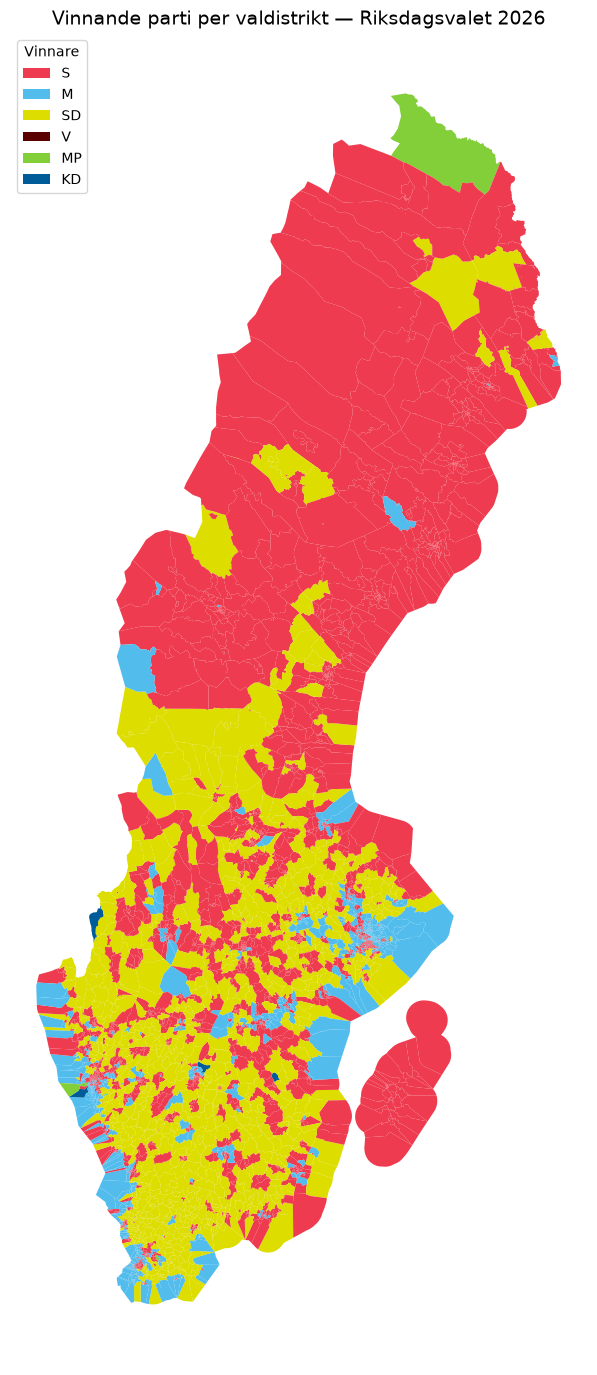

In [119]:
import matplotlib.pyplot as plt

# Merge vinnare med geometri
distrikt_geo['Valdistriktskod'] = distrikt_geo['Valdistriktskod'].astype(int)
karta_data = distrikt_geo.merge(vinnare, on='Valdistriktskod', how='left')

# Partifärger (standard svensk politisk konvention)
partifärger = {
    'Arbetarepartiet-Socialdemokraterna': '#EE3B4F',
    'Moderaterna': '#52BDEC',
    'Sverigedemokraterna': '#DDDD00',
    'Vänsterpartiet': '#5A0000',
    'Miljöpartiet de gröna': '#83CF39',
    'Kristdemokraterna': '#005B99',
    'Centerpartiet': '#009933',
    'Liberalerna (tidigare Folkpartiet)': '#006AB3',
}

karta_data['färg'] = karta_data['Vinnare'].map(partifärger)

# Plotta
fig, ax = plt.subplots(figsize=(10, 14))
karta_data.plot(color=karta_data['färg'], ax=ax, edgecolor='none')
ax.set_axis_off()
ax.set_title('Vinnande parti per valdistrikt — Riksdagsvalet 2026', fontsize=14)

# Enkel legend
from matplotlib.patches import Patch

förkort = {
    'Arbetarepartiet-Socialdemokraterna': 'S',
    'Moderaterna': 'M',
    'Sverigedemokraterna': 'SD',
    'Vänsterpartiet': 'V',
    'Miljöpartiet de gröna': 'MP',
    'Kristdemokraterna': 'KD',
    'Centerpartiet': 'C',
    'Liberalerna (tidigare Folkpartiet)': 'L',
}

legend_elements = [
    Patch(facecolor=partifärger[parti], label=förkort[parti])
    for parti in partifärger
    if parti in karta_klippt['Vinnare'].unique()
]

ax.legend(
    handles=legend_elements,
    loc='upper left',
    fontsize=10,
    frameon=True,
    title='Vinnare',
)


plt.tight_layout()
plt.show()

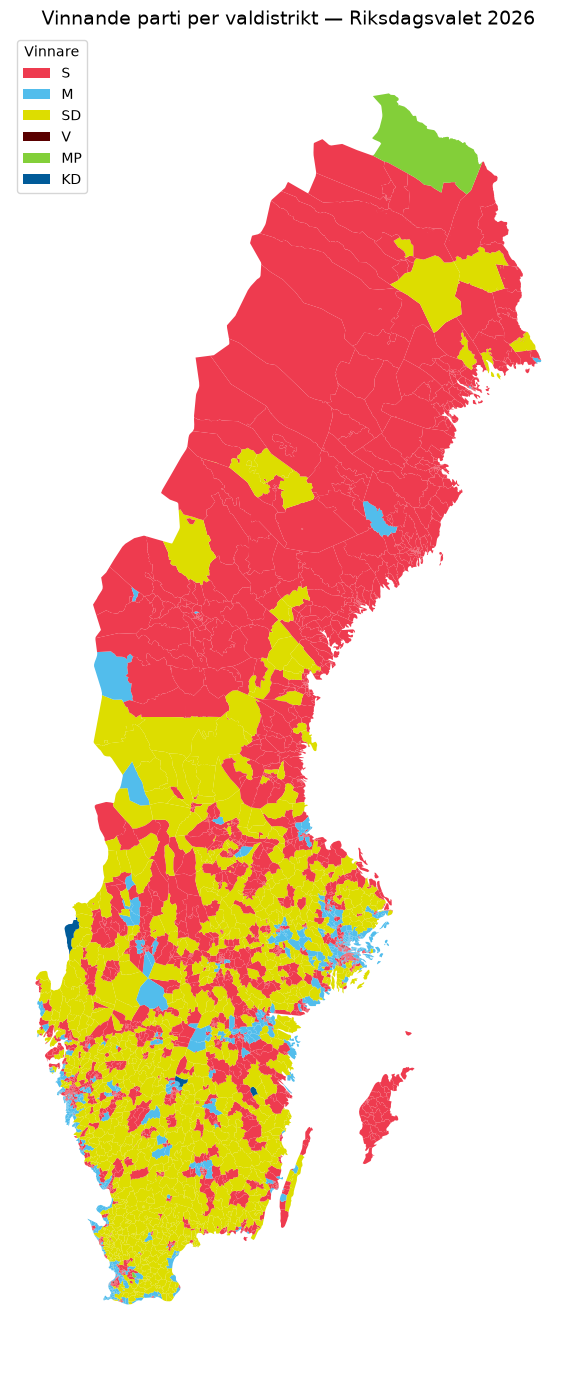

In [120]:
# OK, det var ju fult! Vem kom på den lysande idén att ta med territorialvattengränsen i kartan över valdistrikt?


förkort = {
    'Arbetarepartiet-Socialdemokraterna': 'S',
    'Moderaterna': 'M',
    'Sverigedemokraterna': 'SD',
    'Vänsterpartiet': 'V',
    'Miljöpartiet de gröna': 'MP',
    'Kristdemokraterna': 'KD',
    'Centerpartiet': 'C',
    'Liberalerna (tidigare Folkpartiet)': 'L',
}

fig, ax = plt.subplots(figsize=(10, 14))
karta_klippt.plot(color=karta_klippt['färg'], ax=ax, edgecolor='none')
ax.set_axis_off()
ax.set_title('Vinnande parti per valdistrikt — Riksdagsvalet 2026', fontsize=14)

legend_elements = [
    Patch(facecolor=partifärger[parti], label=förkort[parti])
    for parti in partifärger
    if parti in karta_klippt['Vinnare'].unique()
]

ax.legend(
    handles=legend_elements,
    loc='upper left',
    fontsize=10,
    frameon=True,
    title='Vinnare',
)

plt.tight_layout()
plt.show()

In [121]:
# Väldigt gul karta, kan det stämma? Landbygdsdistrik är visserligen ytmässigt stora och befolkningsglesa, men är SD så starka hela vägen upp i Dalarna?
# För varje SD-vinst, hur stor är marginalen?
sd_vinster = riks_bara_full[
    riks_bara_full['Valdistriktskod'].isin(
        vinnare[vinnare['Vinnare'] == 'Sverigedemokraterna']['Valdistriktskod']
    )
]

# Tvåstörsta parti per distrikt
topp2 = (
    sd_vinster
    .sort_values(['Valdistriktskod', 'Röster'], ascending=[True, False])
    .groupby('Valdistriktskod')
    .head(2)
)

# Beräkna marginal
marginaler = (
    topp2
    .groupby('Valdistriktskod')
    .agg(Vinnare_röster=('Röster', 'max'), Tvåa_röster=('Röster', 'min'))
)
marginaler['Marginal'] = marginaler['Vinnare_röster'] - marginaler['Tvåa_röster']

print(marginaler['Marginal'].describe())
print()
print('Andel SD-vinster inom 20 röster:', (marginaler['Marginal'] <= 20).mean())

count    946.000000
mean      63.766385
std       54.791547
min        1.000000
25%       21.000000
50%       51.000000
75%       92.000000
max      302.000000
Name: Marginal, dtype: float64

Andel SD-vinster inom 20 röster: 0.24841437632135308


In [122]:
# Vinnande riksparti per distrikt, kommunvalet
kriks_bara_full = kommun_roster[kommun_roster['Parti/kategori'].isin(rikspartier)]

vinnare_k = (
    kriks_bara_full
    .loc[kriks_bara_full.groupby('Valdistriktskod')['Röster'].idxmax()]
    [['Valdistriktskod', 'Parti/kategori', 'Röster']]
    .rename(columns={'Parti/kategori': 'Vinnare'})
)

print(vinnare_k['Vinnare'].value_counts())

Vinnare
Arbetarepartiet-Socialdemokraterna    3992
Moderaterna                           1850
Sverigedemokraterna                    435
Centerpartiet                          146
Vänsterpartiet                          98
Kristdemokraterna                       56
Liberalerna (tidigare Folkpartiet)      28
Miljöpartiet de gröna                   21
Name: count, dtype: int64


In [123]:
# Vinnare över alla partier (exklusive summeringskategorier)
inte_parti = kategorier  # samma lista som förut: Summa, Valdeltagande osv

alla_partier = kommun_roster[~kommun_roster['Parti/kategori'].isin(inte_parti)]

vinnare_alla = (
    alla_partier
    .loc[alla_partier.groupby('Valdistriktskod')['Röster'].idxmax()]
    [['Valdistriktskod', 'Parti/kategori', 'Röster']]
    .rename(columns={'Parti/kategori': 'Vinnare'})
)

# Kategorisera: riksparti eller lokalt
vinnare_alla['Kategori'] = vinnare_alla['Vinnare'].where(
    vinnare_alla['Vinnare'].isin(rikspartier),
    'Lokalt parti'
)

print(vinnare_alla['Kategori'].value_counts())

Kategori
Arbetarepartiet-Socialdemokraterna    3911
Moderaterna                           1824
Sverigedemokraterna                    417
Centerpartiet                          143
Lokalt parti                           133
Vänsterpartiet                          98
Kristdemokraterna                       52
Liberalerna (tidigare Folkpartiet)      27
Miljöpartiet de gröna                   21
Name: count, dtype: int64


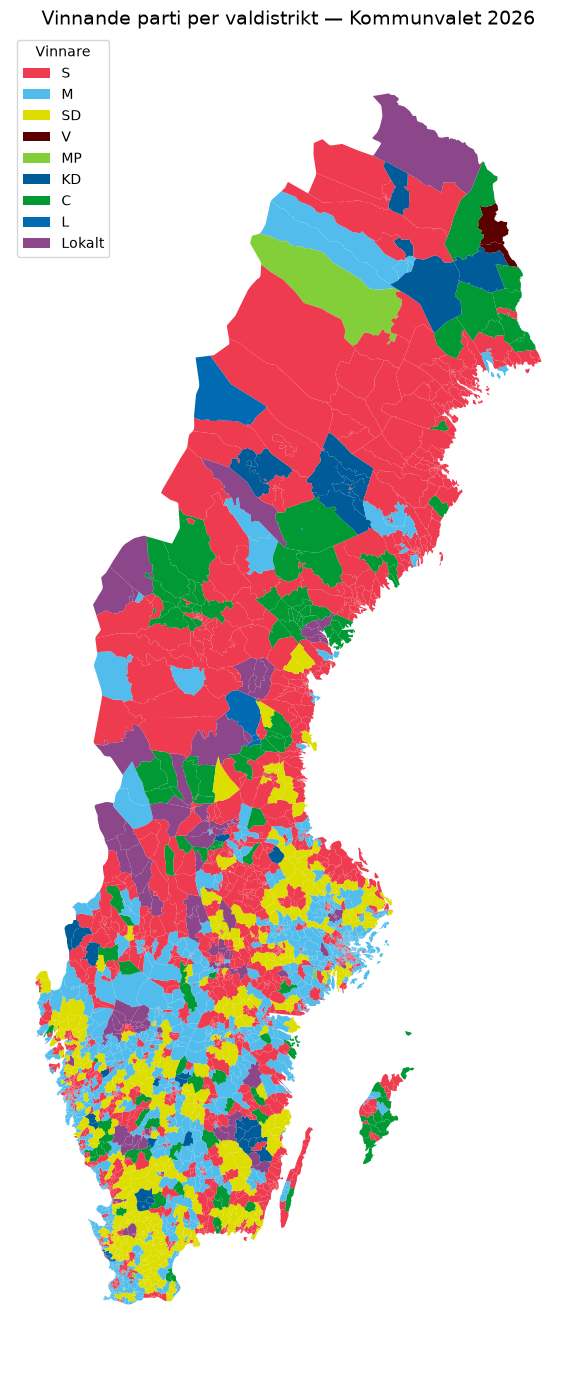

In [124]:
partifärger_k = {
    'Arbetarepartiet-Socialdemokraterna': '#EE3B4F',
    'Moderaterna': '#52BDEC',
    'Sverigedemokraterna': '#DDDD00',
    'Vänsterpartiet': '#5A0000',
    'Miljöpartiet de gröna': '#83CF39',
    'Kristdemokraterna': '#005B99',
    'Centerpartiet': '#009933',
    'Liberalerna (tidigare Folkpartiet)': '#006AB3',
    'Lokalt parti': '#8B4789',
}

förkort_k = {
    'Arbetarepartiet-Socialdemokraterna': 'S',
    'Moderaterna': 'M',
    'Sverigedemokraterna': 'SD',
    'Vänsterpartiet': 'V',
    'Miljöpartiet de gröna': 'MP',
    'Kristdemokraterna': 'KD',
    'Centerpartiet': 'C',
    'Liberalerna (tidigare Folkpartiet)': 'L',
    'Lokalt parti': 'Lokalt',
}

karta_data_k = distrikt_geo.merge(vinnare_alla, on='Valdistriktskod', how='left')
karta_data_k['färg'] = karta_data_k['Kategori'].map(partifärger_k).fillna('#CCCCCC')

karta_klippt_k = karta_data_k.clip(sverige)

fig, ax = plt.subplots(figsize=(10, 14))
karta_klippt_k.plot(color=karta_klippt_k['färg'], ax=ax, edgecolor='none')
ax.set_axis_off()
ax.set_title('Vinnande parti per valdistrikt — Kommunvalet 2026', fontsize=14)

legend_elements = [
    Patch(facecolor=partifärger_k[parti], label=förkort_k[parti])
    for parti in partifärger_k
    if parti in karta_klippt_k['Kategori'].unique()
]

ax.legend(
    handles=legend_elements,
    loc='upper left',
    fontsize=10,
    frameon=True,
    title='Vinnare',
)

plt.tight_layout()
plt.show()

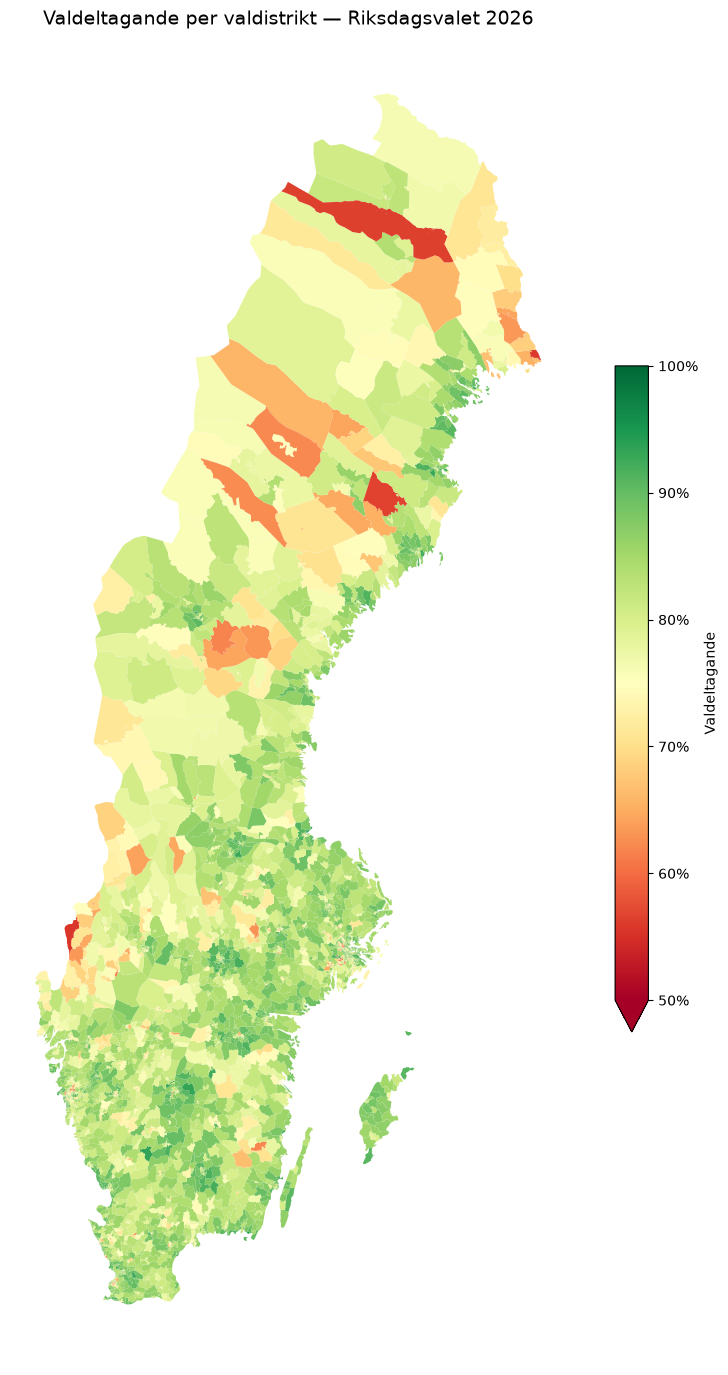

In [125]:
from matplotlib.ticker import PercentFormatter

delt['Deltagande'] = (delt['Röster'] / delt['Röstberättigade']) * 100

delt_karta = distrikt_geo.merge(
    delt[['Valdistriktskod', 'Deltagande']],
    on='Valdistriktskod',
    how='left'
)

delt_klippt = delt_karta.clip(sverige)

fig, ax = plt.subplots(figsize=(10, 14))
delt_klippt.plot(
    column='Deltagande',
    ax=ax,
    cmap='RdYlGn',
    edgecolor='none',
    legend=True,
    legend_kwds={'label': 'Valdeltagande', 'shrink': 0.5},
    vmin=50,
    vmax=100,
)
ax.set_axis_off()
ax.set_title('Valdeltagande per valdistrikt — Riksdagsvalet 2026', fontsize=14)

# Hitta colorbar-axeln och formatera med %
cbar = fig.axes[-1]
cbar.yaxis.set_major_formatter(PercentFormatter(decimals=0))

plt.tight_layout()
plt.show()

In [126]:
# Alla småpartier i riksdagsvalet (dvs. partier i roster som inte är rikspartier eller summeringar)
små = roster[
    ~roster['Parti/kategori'].isin(rikspartier)
    & ~roster['Parti/kategori'].isin(kategorier)
].copy()

# Summera totalt per parti
små_total = små.groupby('Parti/kategori')['Röster'].sum()

# Behåll bara partier med > 100 röster totalt
stora_nog = små_total[små_total > 100].index
små_filter = små[små['Parti/kategori'].isin(stora_nog)]

# Hitta topp-distrikt per parti
topp_distrikt = (
    små_filter
    .loc[små_filter.groupby('Parti/kategori')['Röster'].idxmax()]
    [['Parti/kategori', 'Valdistriktsnamn', 'Kommunnamn', 'Länsnamn', 'Röster']]
    .rename(columns={'Röster': 'Röster i toppdistrikt'})
)

# Lägg till partiets totala röster i hela landet
topp_distrikt = topp_distrikt.merge(
    små_total.rename('Totalt i riket').reset_index(),
    on='Parti/kategori'
)

# Sortera på totalt riksresultat
topp_distrikt = topp_distrikt.sort_values('Totalt i riket', ascending=False)

print(topp_distrikt.to_string(index=False))

                           Parti/kategori         Valdistriktsnamn Kommunnamn        Länsnamn  Röster i toppdistrikt  Totalt i riket
                            Örebropartiet                 Pålsboda  Hallsberg          Örebro                     98           39644
                   Alternativ för Sverige   Uppsamlingsdistrikt 00   Göteborg Västra Götaland                     83           26729
                     Kristna Värdepartiet           Kiruna nordost     Kiruna      Norrbotten                     33            9017
                         Ambition Sverige   Uppsamlingsdistrikt 00   Göteborg Västra Götaland                     19            7679
                             Piratpartiet   Uppsamlingsdistrikt 00   Göteborg Västra Götaland                     41            7464
                     Medborgerlig Samling   Uppsamlingsdistrikt 00    Uppsala         Uppsala                      9            4118
MoD - Mänskliga rättigheter och Demokrati   Uppsamlingsdistrikt 00   

In [127]:
# Småpartier får tydligen många röster i uppsamlingsdistrik, vad händer om vi bortser från dem?

små = roster[
    ~roster['Parti/kategori'].isin(rikspartier)
    & ~roster['Parti/kategori'].isin(kategorier)
    & ~roster['Valdistriktsnamn'].str.contains('Uppsamlingsdistrikt', case=False)
].copy()

små_total = små.groupby('Parti/kategori')['Röster'].sum()
stora_nog = små_total[små_total > 100].index
små_filter = små[små['Parti/kategori'].isin(stora_nog)]

topp_distrikt = (
    små_filter
    .loc[små_filter.groupby('Parti/kategori')['Röster'].idxmax()]
    [['Parti/kategori', 'Valdistriktsnamn', 'Kommunnamn', 'Länsnamn', 'Röster']]
    .rename(columns={'Röster': 'Röster i toppdistrikt'})
)

topp_distrikt = topp_distrikt.merge(
    små_total.rename('Totalt exkl. uppsamling').reset_index(),
    on='Parti/kategori'
)

topp_distrikt = topp_distrikt.sort_values('Totalt exkl. uppsamling', ascending=False)

print(topp_distrikt.to_string(index=False))


                           Parti/kategori                     Valdistriktsnamn Kommunnamn        Länsnamn  Röster i toppdistrikt  Totalt exkl. uppsamling
                            Örebropartiet                             Pålsboda  Hallsberg          Örebro                     98                    37304
                   Alternativ för Sverige                            Nol norra        Ale Västra Götaland                     20                    25022
                     Kristna Värdepartiet                       Kiruna nordost     Kiruna      Norrbotten                     33                     8469
                         Ambition Sverige                           Funäsdalen Härjedalen        Jämtland                     15                     7214
                             Piratpartiet                           Lillporsön      Luleå      Norrbotten                     11                     6951
                     Medborgerlig Samling                               Brev

SLutsats: Småpartier får i stort sett bara ströröster, enda riktiga undantaget är Örebropartiet som har ett geografiskt fäste. 
